# EDA: Citi Bike trips 2016–2017 (raw Bronze data, all columns)

Exploratory analysis of the **raw** trip data, before any cleaning, so the findings can decide the Silver cleaning rules
and the Gold features. It reads the daily Bronze files (exact copies of the CSVs) and looks at all 15 columns.

| Part | Question | Feeds into |
|---|---|---|
| A. Data quality | What is missing, broken, duplicated or implausible in each column? | Silver rules |
| B. Demand over time | Trend, seasonality, weekly / hourly patterns, unusual days | Gold features, time split |
| C. Stations | How many, churn, renamed / moved stations, test or depot stations | Silver rules, Gold grid |
| D. The target | Station-day trip starts: distribution, zeros, autocorrelation, lag-7 baseline | Gold features, model choice |
| E. Riders | User type, birth year, gender | Why Silver drops these columns |
| F. Findings | One table: finding → decision | Report |

Spark does the heavy lifting on ~30M trips; only small aggregated tables go to pandas for plots.
The full run takes a while (roughly 20–40 minutes on a laptop). To try it quickly first, set `MONTHS` in the next cell.

In [1]:
import os
import glob

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import pyspark
import pyspark.sql.functions as F
from pyspark.sql.functions import col
from pyspark.sql.window import Window

# run from scripts/ so paths match the pipeline scripts ("datamart/...")
os.chdir("/opt/airflow/scripts")
import utils.data_processing_silver_table as silver   # reuse Silver's column-name map and date parser

# None = all of 2016-2017. For a quick first run use e.g. ["2016-01", "2016-07", "2017-01", "2017-07"]
MONTHS = None

spark = pyspark.sql.SparkSession.builder \
    .appName("eda") \
    .master("local[4]") \
    .config("spark.driver.memory", "4g") \
    .config("spark.ui.showConsoleProgress", "false") \
    .config("spark.sql.legacy.timeParserPolicy", "CORRECTED") \
    .config("spark.sql.sources.partitionColumnTypeInference.enabled", "false") \
    .getOrCreate()
spark.sparkContext.setLogLevel("ERROR")

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (12, 4)
os.makedirs("eda_figures", exist_ok=True)   # charts are also saved here for the report

def save(name):
    plt.savefig("eda_figures/" + name + ".png", bbox_inches="tight")
    plt.show()

/home/airflow/.local/lib/python3.10/site-packages/pyspark/bin/load-spark-env.sh: line 68: ps: command not found
Setting default log level to "WARN".
To adjust logging level use sc.setLogLevel(newLevel). For SparkR, use setLogLevel(newLevel).
26/10/16 23:19:50 WARN NativeCodeLoader: Unable to load native-hadoop library for your platform... using builtin-java classes where applicable


In [2]:
# load the daily Bronze files (all columns are raw text)
bronze_files = sorted(glob.glob("datamart/bronze/trips/bronze_trips_*.parquet"))
if MONTHS:
    bronze_files = [f for f in bronze_files if f.split("bronze_trips_")[1][:7].replace("_", "-") in MONTHS]
print("bronze files:", len(bronze_files))

# months use two header styles ("tripduration" vs "Trip Duration"). Reading all files at once would make Spark use
# only one file's column names, and the other style's columns would come back empty. So we read one month at a time
# (a month always has one header style) and rename to one set of names (same mapping Silver uses).
def rename_to_clean(d):
    cols = []
    for raw_key, clean_name in silver.column_name_map.items():
        matches = [c for c in d.columns if c.lower().replace(" ", "") == raw_key]
        cols.append(F.coalesce(*[col("`" + c + "`") for c in matches]).alias(clean_name) if matches
                    else F.lit(None).cast("string").alias(clean_name))
    return d.select(*cols, "source_file", "snapshot_date")

files_by_month = {}
for f in bronze_files:
    files_by_month.setdefault(f.split("bronze_trips_")[1][:7], []).append(f)

# typed copy of every column next to the raw text, so we can count values that fail to parse
def add_typed_columns(raw):
        return raw.select(
        "*",
        F.trim(col("trip_duration")).cast("int").alias("duration_s"),
        silver.parse_trip_timestamp(col("start_time")).alias("start_ts"),
        silver.parse_trip_timestamp(col("stop_time")).alias("stop_ts"),
        F.trim(col("start_station_latitude")).cast("double").alias("start_lat"),
        F.trim(col("start_station_longitude")).cast("double").alias("start_lon"),
        F.trim(col("end_station_latitude")).cast("double").alias("end_lat"),
        F.trim(col("end_station_longitude")).cast("double").alias("end_lon"),
        F.trim(col("birth_year")).cast("int").alias("birth_year_int"),
        F.trim(col("gender")).cast("int").alias("gender_int"),
    ).withColumn("start_date", F.to_date("start_ts")).withColumn("start_hour", F.hour("start_ts"))

# two years (~30M rows) are too big to hold in memory on a laptop, so we save a cleaned-up copy to disk ONE MONTH
# AT A TIME (small jobs, low memory) and then read it back. Later cells read only the columns they need from disk.
# A month that is already saved is skipped, so if this cell crashes you can just run it again and it continues.
eda_path = "datamart/eda/trips_eda"
for m, month_files in sorted(files_by_month.items()):
    month_dir = eda_path + "/month=" + m.replace("_", "-")
    if os.path.exists(month_dir + "/_SUCCESS"):
        continue
    month_df = add_typed_columns(rename_to_clean(spark.read.parquet(*month_files)))  # one month = one header style
    month_df.coalesce(2).write.mode("overwrite").parquet(month_dir)
    print("saved", m.replace("_", "-"))

month_dirs = [eda_path + "/month=" + m.replace("_", "-") for m in sorted(files_by_month)]
df = spark.read.option("basePath", eda_path).parquet(*month_dirs)

N = df.count()
print("total trips (raw):", N)
df.select(list(silver.column_name_map.values())).show(3, truncate=False)

bronze files: 731
saved 2016-01
saved 2016-02
saved 2016-03
saved 2016-04
saved 2016-05
saved 2016-06
saved 2016-07
saved 2016-08
saved 2016-09
saved 2016-10
saved 2016-11
saved 2016-12
saved 2017-01
saved 2017-02
saved 2017-03
saved 2017-04
saved 2017-05
saved 2017-06
saved 2017-07
saved 2017-08
saved 2017-09
saved 2017-10
saved 2017-11
saved 2017-12
total trips (raw): 30210312
+-------------+-------------------+-------------------+----------------+---------------------+----------------------+-----------------------+--------------+-------------------+--------------------+---------------------+-------+----------+----------+------+
|trip_duration|start_time         |stop_time          |start_station_id|start_station_name   |start_station_latitude|start_station_longitude|end_station_id|end_station_name   |end_station_latitude|end_station_longitude|bike_id|user_type |birth_year|gender|
+-------------+-------------------+-------------------+----------------+---------------------+----------

# Part A. Data quality (decides the Silver rules)

### A1. Volume and file formats per month

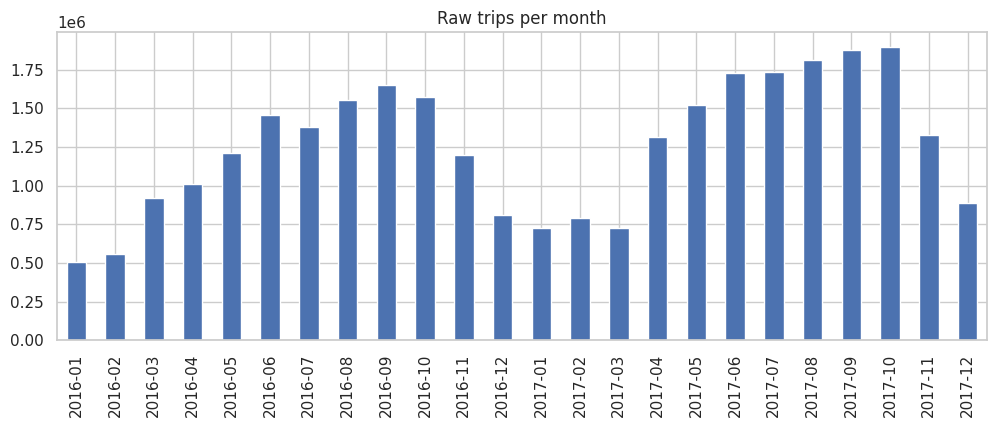

,month,trips,csv_files,pct_M/d/yyyy_dates
19,2016-01,509478,1,100.0
2,2016-02,560874,1,100.0
9,2016-03,919921,1,100.0
16,2016-04,1013149,2,100.0
15,2016-05,1212280,2,100.0
21,2016-06,1460318,2,100.0
20,2016-07,1380110,2,100.0
22,2016-08,1557663,2,100.0
8,2016-09,1648856,2,100.0
11,2016-10,1573872,2,0.0


In [3]:
# rows per month, how many CSV files, which date format and header style
fmt = df.groupBy("month").agg(
    F.count("*").alias("trips"),
    F.countDistinct("source_file").alias("csv_files"),
    F.round(100 * F.mean(col("start_time").contains("/").cast("int")), 1).alias("pct_M/d/yyyy_dates"),
).toPandas().sort_values("month")
ax = fmt.plot(x="month", y="trips", kind="bar", legend=False); ax.set_title("Raw trips per month"); ax.set_xlabel("")
save("A1_trips_per_month")
fmt

### A2. Missing values in every column
Counts empty strings and the text placeholders `\\N` and `NULL` as missing too.

In [4]:
def c_null(v):
    return v.isNull() | (v == "") | (F.upper(v).isin("\\N", "NULL", "NAN"))

raw_cols = list(silver.column_name_map.values())
missing = df.select([F.sum(c_null(F.trim(col(c))).cast("int")).alias(c) for c in raw_cols]).toPandas().T
missing.columns = ["missing"]
missing["missing_pct"] = (100 * missing["missing"] / N).round(3)
missing

,missing,missing_pct
trip_duration,0,0.000
start_time,0,0.000
stop_time,0,0.000
start_station_id,0,0.000
start_station_name,0,0.000
start_station_latitude,0,0.000
start_station_longitude,0,0.000
end_station_id,0,0.000
end_station_name,0,0.000
end_station_latitude,0,0.000


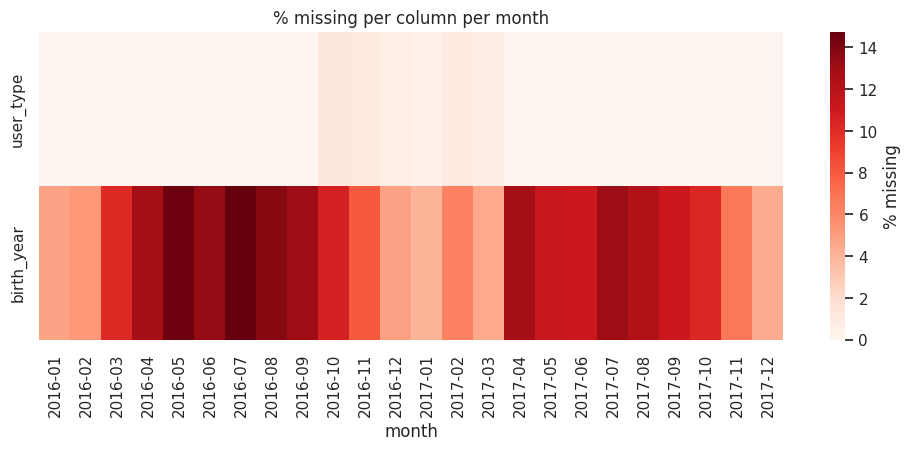

,user_type,birth_year
month,,
2016-01,0.00,4.82
2016-02,0.00,5.32
2016-03,0.00,10.14
2016-04,0.00,12.88
2016-05,0.00,14.54
2016-06,0.00,13.37
2016-07,0.00,14.75
2016-08,0.00,13.78
2016-09,0.00,13.07


In [5]:
# missing values by month for the columns that have any (shows whether a column is missing in whole periods)
cols_with_missing = missing[missing["missing"] > 0].index.tolist()
if cols_with_missing:
    by_month = df.groupBy("month").agg(*[F.round(100 * F.mean(c_null(F.trim(col(c))).cast("int")), 2).alias(c)
                                         for c in cols_with_missing]).toPandas().sort_values("month").set_index("month")
    ax = sns.heatmap(by_month.T, cmap="Reds", annot=False, cbar_kws={"label": "% missing"})
    ax.set_title("% missing per column per month"); save("A2_missing_by_month")
    display(by_month)

### A3. Values that are present but fail to parse

In [6]:
def unparseable(raw_c, typed_c):
    return (~c_null(F.trim(col(raw_c))) & col(typed_c).isNull()).cast("int")

bad = df.select(
    F.sum(unparseable("trip_duration", "duration_s")).alias("trip_duration"),
    F.sum(unparseable("start_time", "start_ts")).alias("start_time"),
    F.sum(unparseable("stop_time", "stop_ts")).alias("stop_time"),
    F.sum(unparseable("start_station_latitude", "start_lat")).alias("start_station_latitude"),
    F.sum(unparseable("start_station_longitude", "start_lon")).alias("start_station_longitude"),
    F.sum(unparseable("end_station_latitude", "end_lat")).alias("end_station_latitude"),
    F.sum(unparseable("end_station_longitude", "end_lon")).alias("end_station_longitude"),
    F.sum(unparseable("birth_year", "birth_year_int")).alias("birth_year"),
    F.sum(unparseable("gender", "gender_int")).alias("gender"),
).toPandas().T
bad.columns = ["present_but_unparseable"]
bad

,present_but_unparseable
trip_duration,0
start_time,0
stop_time,0
start_station_latitude,0
start_station_longitude,0
end_station_latitude,0
end_station_longitude,0
birth_year,0
gender,0


In [7]:
# examples of unparseable values, if any
for raw_c, typed_c in [("start_time", "start_ts"), ("trip_duration", "duration_s"), ("birth_year", "birth_year_int")]:
    ex = df.filter(~c_null(F.trim(col(raw_c))) & col(typed_c).isNull()).groupBy(raw_c).count().orderBy(F.desc("count")).limit(5).toPandas()
    if len(ex):
        print(raw_c); display(ex)

### A4. Duplicates

In [8]:
n_distinct_rows = df.select(raw_cols).distinct().count()
n_bike_start = df.select("bike_id", "start_time").distinct().count()
print("exact duplicate rows:", N - n_distinct_rows)
print("rows sharing bike_id + start_time with another row:", N - n_bike_start)

exact duplicate rows: 0
rows sharing bike_id + start_time with another row: 0


### A5. Trip duration and time logic

In [9]:
dur = df.select(
    F.sum((col("duration_s") < 60).cast("int")).alias("under_60s"),
    F.sum((col("duration_s") > 3 * 3600).cast("int")).alias("over_3h"),
    F.sum((col("duration_s") > 24 * 3600).cast("int")).alias("over_24h"),
    F.sum((col("duration_s") > 7 * 24 * 3600).cast("int")).alias("over_7d"),
    F.max("duration_s").alias("max_seconds"),
    F.sum((col("stop_ts") < col("start_ts")).cast("int")).alias("stop_before_start"),
    # does trip_duration agree with stop - start? (more than 2 minutes off)
    F.sum((F.abs(col("stop_ts").cast("long") - col("start_ts").cast("long") - col("duration_s")) > 120).cast("int")).alias("duration_mismatch_over_2min"),
    F.sum((col("start_date") != col("snapshot_date")).cast("int")).alias("start_not_on_snapshot_day"),
).toPandas().T
dur.columns = ["rows"]
dur

,rows
under_60s,0
over_3h,63709
over_24h,7746
over_7d,1250
max_seconds,9735948
stop_before_start,132
duration_mismatch_over_2min,517
start_not_on_snapshot_day,0


count    604007.0
mean         16.4
std         232.8
min           1.0
1%            1.9
50%          10.4
90%          27.3
99%          57.9
99.9%       357.7
max      100896.5
Name: minutes, dtype: float64


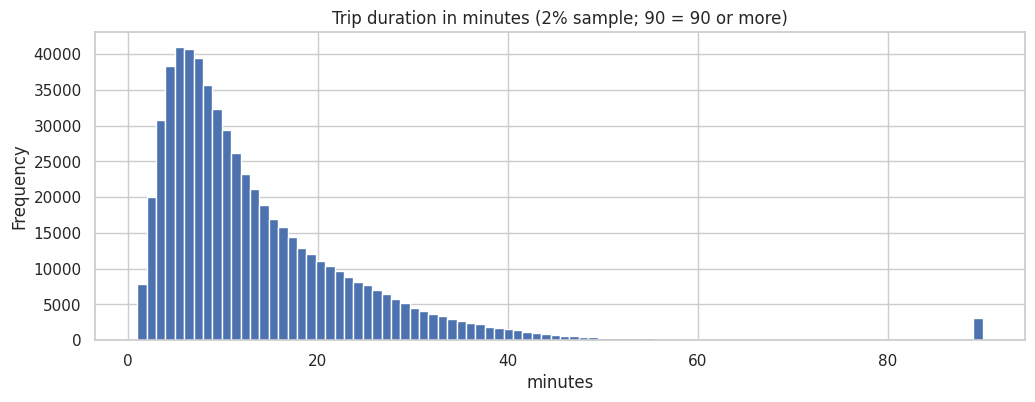

In [10]:
# duration distribution (2% sample)
sample = df.select((col("duration_s") / 60).alias("minutes")).sample(fraction=0.02, seed=42).toPandas()
print(sample["minutes"].describe(percentiles=[0.01, 0.5, 0.9, 0.99, 0.999]).round(1))
ax = sample["minutes"].clip(upper=90).plot(kind="hist", bins=90)
ax.set_title("Trip duration in minutes (2% sample; 90 = 90 or more)"); ax.set_xlabel("minutes")
save("A5_trip_duration")

In [11]:
# daylight saving time: the clock change days have 23 / 25 hours, check trips around 1-3am on those days
dst_days = ["2016-03-13", "2016-11-06", "2017-03-12", "2017-11-05"]
df.filter(col("start_date").isin(dst_days)).groupBy("start_date", "start_hour").count() \
  .filter(col("start_hour") <= 3).orderBy("start_date", "start_hour").toPandas()

,start_date,start_hour,count
0,2016-03-13,0,429
1,2016-03-13,1,295
2,2016-03-13,3,206
3,2016-11-06,0,711
4,2016-11-06,1,781
5,2016-11-06,2,187
6,2016-11-06,3,121
7,2017-03-12,0,200
8,2017-03-12,1,120
9,2017-03-12,3,110


# Part B. Demand over time
### B1. Daily trips, trend and unusual days

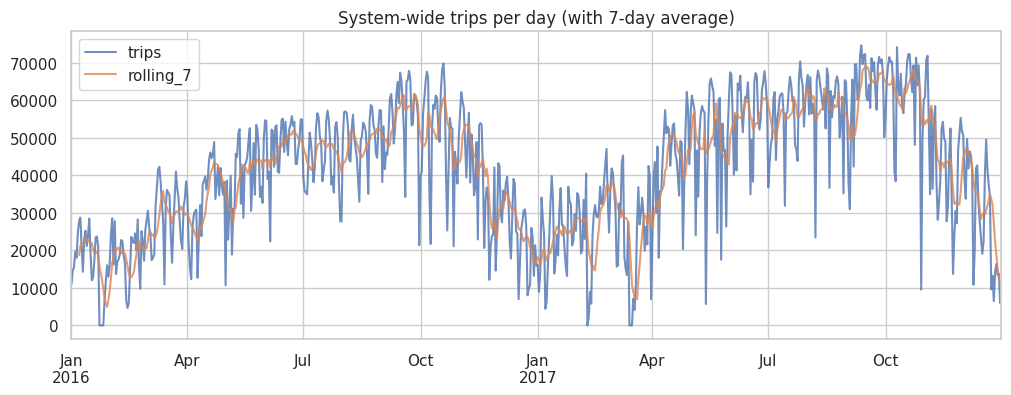

days with 0 trips: [datetime.date(2016, 1, 23), datetime.date(2016, 1, 24), datetime.date(2016, 1, 25), datetime.date(2016, 1, 26), datetime.date(2017, 2, 9), datetime.date(2017, 3, 14), datetime.date(2017, 3, 15), datetime.date(2017, 3, 16)]


In [12]:
daily = df.groupBy("start_date").count().withColumnRenamed("count", "trips").toPandas()
daily["start_date"] = pd.to_datetime(daily["start_date"])
all_days = pd.DataFrame({"start_date": pd.date_range(daily["start_date"].min(), daily["start_date"].max())})
daily = all_days.merge(daily, on="start_date", how="left").fillna({"trips": 0}).sort_values("start_date")
daily["rolling_7"] = daily["trips"].rolling(7).mean()
ax = daily.plot(x="start_date", y=["trips", "rolling_7"], alpha=0.8)
ax.set_title("System-wide trips per day (with 7-day average)"); ax.set_xlabel("")
save("B1_daily_trips")
print("days with 0 trips:", daily[daily["trips"] == 0]["start_date"].dt.date.tolist())

In [13]:
# unusual days: far below the 7-day average around them (storms, heavy rain, holidays)
daily["centered_7"] = daily["trips"].rolling(15, center=True).median()
daily["ratio_to_normal"] = (daily["trips"] / daily["centered_7"]).round(2)
daily.nsmallest(20, "ratio_to_normal")[["start_date", "trips", "centered_7", "ratio_to_normal"]]

,start_date,trips,centered_7,ratio_to_normal
22,2016-01-23,0.0,12718.0,0.00
23,2016-01-24,0.0,12718.0,0.00
24,2016-01-25,0.0,12973.0,0.00
25,2016-01-26,0.0,16028.0,0.00
405,2017-02-09,0.0,23857.0,0.00
438,2017-03-14,0.0,15185.0,0.00
439,2017-03-15,0.0,15185.0,0.00
440,2017-03-16,0.0,15185.0,0.00
406,2017-02-10,1997.0,23857.0,0.08
498,2017-05-13,5704.0,56461.0,0.10


### B2. Monthly level and year-over-year growth

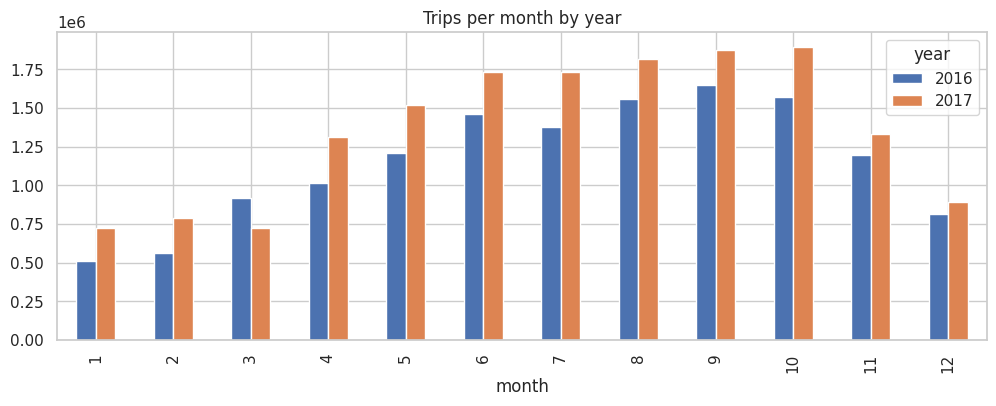

year,2016,2017,growth_pct
month,,,
1,509478.0,726676.0,42.6
2,560874.0,791647.0,41.1
3,919921.0,727665.0,-20.9
4,1013149.0,1315404.0,29.8
5,1212280.0,1523268.0,25.7
6,1460318.0,1731594.0,18.6
7,1380110.0,1735599.0,25.8
8,1557663.0,1816498.0,16.6
9,1648856.0,1878098.0,13.9


In [14]:
monthly = daily.assign(year=daily["start_date"].dt.year, month=daily["start_date"].dt.month) \
               .groupby(["year", "month"])["trips"].sum().unstack(0)
ax = monthly.plot(kind="bar"); ax.set_title("Trips per month by year"); ax.set_xlabel("month")
save("B2_monthly_by_year")
if 2016 in monthly and 2017 in monthly:
    monthly["growth_pct"] = (100 * (monthly[2017] / monthly[2016] - 1)).round(1)
monthly

In [15]:
# mean trips per day in each period of our time split (shows level shift between train / test / OOT)
periods = {"train 2016": ("2016-01-01", "2016-12-31"), "tune 2017 Q1": ("2017-01-01", "2017-03-31"),
           "test 2017 Q2": ("2017-04-01", "2017-06-30"), "OOT 2017 Q3+Q4": ("2017-07-01", "2017-12-31")}
pd.DataFrame([{"period": p, "days": int(daily["start_date"].between(a, b).sum()),
               "mean_trips_per_day": daily[daily["start_date"].between(a, b)]["trips"].mean()}
              for p, (a, b) in periods.items()]).round(0)

,period,days,mean_trips_per_day
0,train 2016,366,37830.0
1,tune 2017 Q1,90,24955.0
2,test 2017 Q2,91,50223.0
3,OOT 2017 Q3+Q4,184,51893.0


### B3. Day of week and hour of day

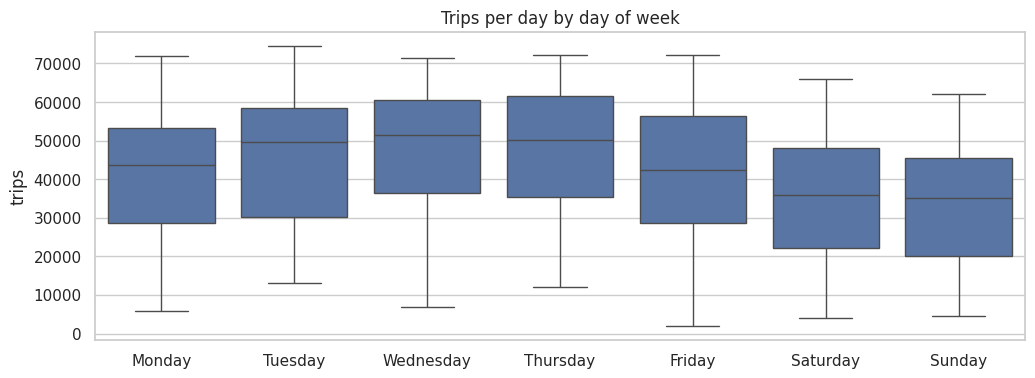

In [16]:
daily["day_of_week"] = daily["start_date"].dt.day_name()
order = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]
ax = sns.boxplot(data=daily[daily["trips"] > 0], x="day_of_week", y="trips", order=order)
ax.set_title("Trips per day by day of week"); ax.set_xlabel("")
save("B3_day_of_week")

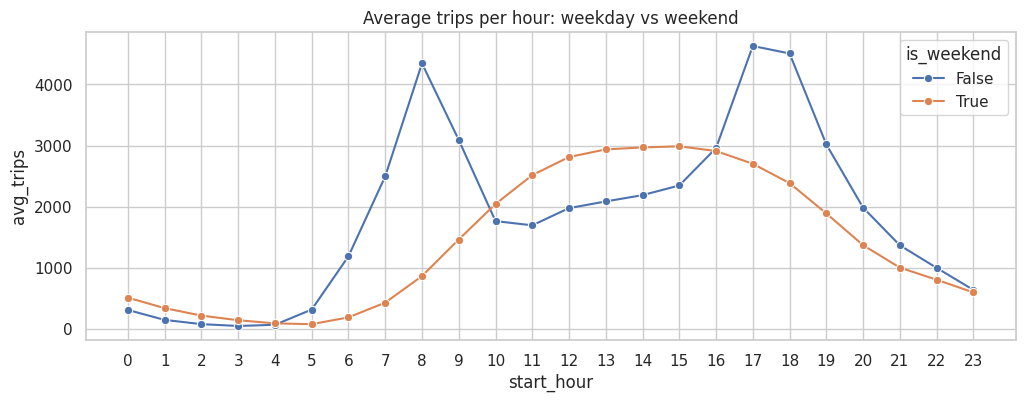

In [17]:
# average trips per hour, weekday vs weekend
hourly = df.filter(col("start_ts").isNotNull()).withColumn("is_weekend", F.dayofweek("start_date").isin(1, 7)) \
           .groupBy("is_weekend", "start_hour").count().toPandas()
n_days = daily.assign(is_weekend=daily["start_date"].dt.dayofweek >= 5).groupby("is_weekend").size()
hourly["avg_trips"] = hourly["count"] / hourly["is_weekend"].map(n_days)
ax = sns.lineplot(data=hourly.sort_values("start_hour"), x="start_hour", y="avg_trips", hue="is_weekend", marker="o")
ax.set_title("Average trips per hour: weekday vs weekend"); ax.set_xticks(range(24))
save("B3_hourly_profile")

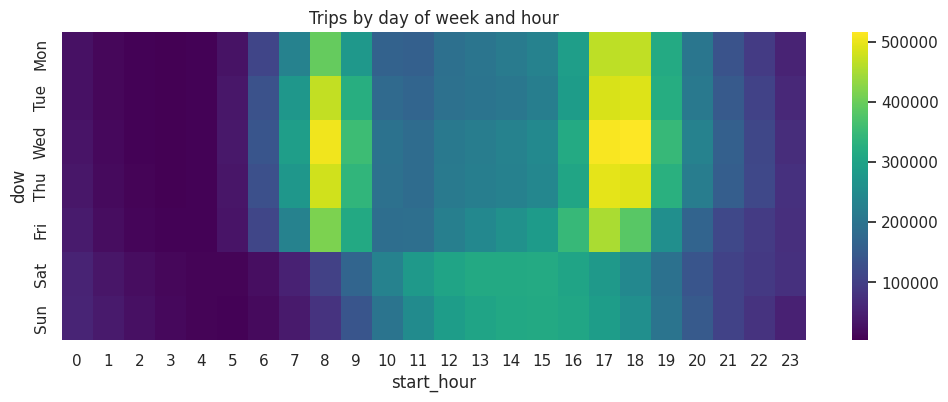

In [18]:
# hour x day-of-week heatmap
hm = df.filter(col("start_ts").isNotNull()).groupBy(F.date_format("start_date", "E").alias("dow"), "start_hour").count().toPandas() \
       .pivot(index="dow", columns="start_hour", values="count").reindex(["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"])
ax = sns.heatmap(hm, cmap="viridis"); ax.set_title("Trips by day of week and hour")
save("B3_dow_hour_heatmap")

# Part C. Stations
### C1. Station IDs, names and coordinates

In [19]:
stations = df.groupBy(col("start_station_id").alias("station_id")).agg(
    F.count("*").alias("trips"),
    F.countDistinct("start_station_name").alias("n_names"),
    F.countDistinct(F.round("start_lat", 4), F.round("start_lon", 4)).alias("n_locations"),
    F.min("start_date").alias("first_day"), F.max("start_date").alias("last_day"),
    F.countDistinct("start_date").alias("active_days"),
    F.first("start_station_name").alias("name"),
    F.avg("start_lat").alias("lat"), F.avg("start_lon").alias("lon"),
).toPandas()
print("start station ids:", len(stations))
print("ids with more than one name:", (stations["n_names"] > 1).sum())
print("ids with more than one location:", (stations["n_locations"] > 1).sum())
names_multi_ids = df.groupBy("start_station_name").agg(F.countDistinct("start_station_id").alias("n_ids")).filter(col("n_ids") > 1).count()
print("names used by more than one id:", names_multi_ids)
stations[stations["n_names"] > 1].sort_values("trips", ascending=False).head(10)

start station ids: 844
ids with more than one name: 21
ids with more than one location: 16
names used by more than one id: 9


,station_id,trips,n_names,n_locations,first_day,last_day,active_days,name,lat,lon
303,3263,131900,2,2,2016-07-05,2017-12-31,541,Cooper Square & Astor Pl,40.729276,-73.990852
804,504,119265,2,1,2016-01-01,2017-12-31,678,1 Ave & E 16 St,40.732219,-73.981656
768,468,98638,2,1,2016-01-01,2017-12-30,721,Broadway & W 56 St,40.765265,-73.981923
192,312,91052,2,1,2016-01-01,2017-12-31,685,Allen St & Stanton St,40.722055,-73.989111
277,3236,90440,2,1,2016-01-04,2017-12-31,695,W 42 St & Dyer Ave,40.758985,-73.993800
832,533,59198,2,1,2016-01-01,2017-12-29,566,Broadway & W 38 St,40.752996,-73.987216
793,493,39421,2,1,2016-01-01,2017-05-26,433,W 45 St & 6 Ave,40.756800,-73.982912
60,250,35504,2,1,2016-01-01,2016-07-19,192,Lafayette St & Jersey St,40.724561,-73.995653
317,329,31531,2,2,2016-01-01,2016-09-30,270,Greenwich St & North Moore St,40.720314,-74.010274
312,3285,26927,2,1,2016-08-01,2017-12-31,512,W 87 St & Amsterdam Ave,40.788390,-73.974700


In [20]:
# coordinates: zero, missing or outside the NYC area (lat 40.4-41.0, lon -74.3 to -73.6)
def outside_nyc(lat, lon):
    return (col(lat) < 40.4) | (col(lat) > 41.0) | (col(lon) < -74.3) | (col(lon) > -73.6)
coords = df.select(
    F.sum((col("start_lat").isNull() | col("start_lon").isNull()).cast("int")).alias("start_missing"),
    F.sum(((col("start_lat") == 0) | (col("start_lon") == 0)).cast("int")).alias("start_zero"),
    F.sum(outside_nyc("start_lat", "start_lon").cast("int")).alias("start_outside_nyc"),
    F.sum((col("end_lat").isNull() | col("end_lon").isNull()).cast("int")).alias("end_missing"),
    F.sum(((col("end_lat") == 0) | (col("end_lon") == 0)).cast("int")).alias("end_zero"),
    F.sum(outside_nyc("end_lat", "end_lon").cast("int")).alias("end_outside_nyc"),
).toPandas().T
coords.columns = ["rows"]
coords

,rows
start_missing,0
start_zero,46
start_outside_nyc,128
end_missing,0
end_zero,161
end_outside_nyc,244


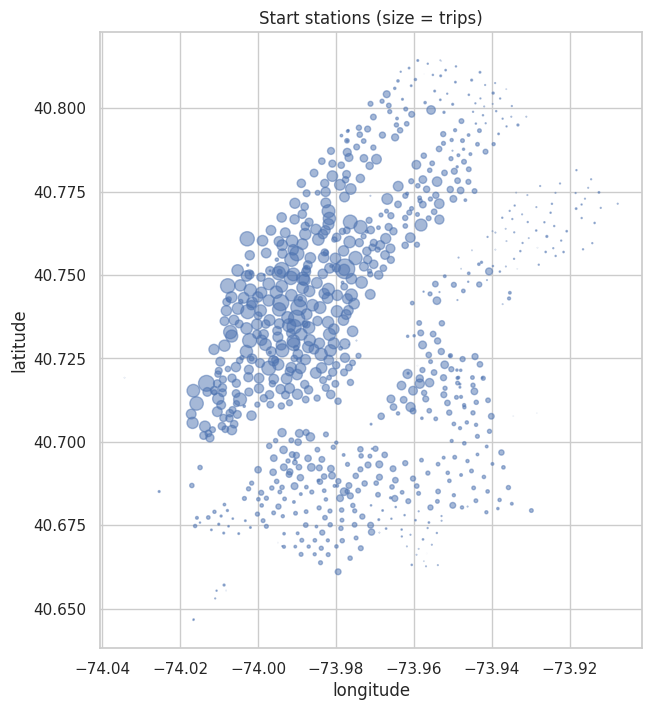

In [21]:
# map of stations (size = trips); outliers show up immediately
inside = stations[(stations["lat"].between(40.4, 41.0)) & (stations["lon"].between(-74.3, -73.6))]
plt.figure(figsize=(7, 8))
plt.scatter(inside["lon"], inside["lat"], s=inside["trips"] / inside["trips"].max() * 200, alpha=0.5)
plt.title("Start stations (size = trips)"); plt.xlabel("longitude"); plt.ylabel("latitude")
save("C1_station_map")

In [22]:
# test / depot / warehouse style stations (not real customer stations)
pattern = "(?i)depot|test|warehouse|lab|nycbs|mobile|8d|kiosk|valet"
stations[stations["name"].fillna("").str.contains(pattern)].sort_values("trips", ascending=False)

,station_id,trips,n_names,n_locations,first_day,last_day,active_days,name,lat,lon
271,3230,60198,1,1,2016-01-04,2017-02-19,288,Penn Station Valet,40.751284,-73.996924
132,3065,6799,1,1,2016-01-01,2017-12-31,699,Union Ave & Wallabout St,40.700295,-73.950323
482,3450,1670,1,1,2017-02-23,2017-04-13,21,Penn Station Valet - Valet Scan,40.751284,-73.996924
65,255,1313,1,1,2016-07-01,2017-05-07,221,NYCBS Depot - SSP,40.646768,-74.016510
287,3245,627,3,3,2016-07-06,2017-10-04,125,NYCBS DEPOT - DELANCEY,40.653082,-74.010980
467,3432,495,2,2,2016-09-22,2017-12-29,183,NYCBS Depot - GOW,40.668766,-73.993777
262,3219,323,1,1,2016-07-01,2017-05-29,182,NYCBS Depot - STY,40.729193,-73.976655
498,3468,209,1,1,2017-05-30,2017-12-30,119,NYCBS Depot - STY - Garage 4,40.730380,-73.974750
677,3650,66,1,1,2017-11-16,2017-12-22,12,8D Mobile 01,45.505851,-73.569109
282,3240,51,1,2,2016-12-09,2017-05-15,45,NYCBS Depot BAL - DYR,38.361440,-69.641279


In [23]:
# round trips: start station = end station (often leisure rides, or bikes re-docked)
rt = df.select(F.mean((col("start_station_id") == col("end_station_id")).cast("int")).alias("share_round_trips")).toPandas()
rt

,share_round_trips
0,0.019271


### C2. Station churn and concentration

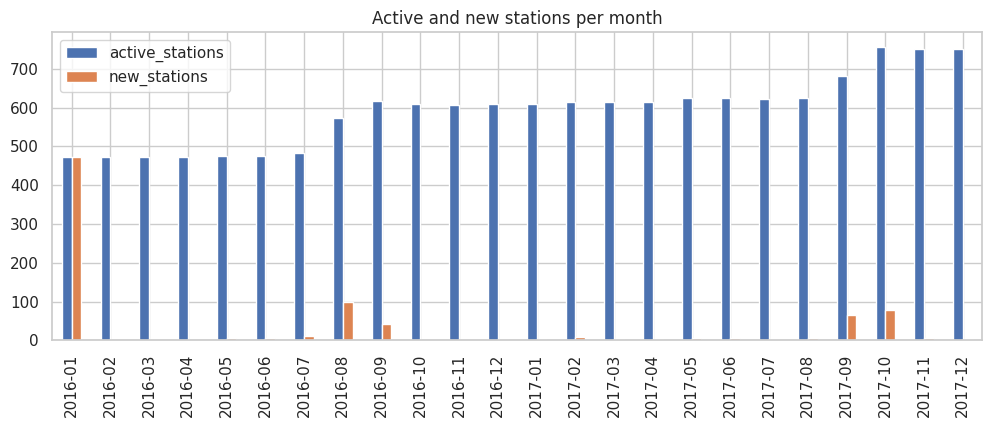

,month,active_stations,new_stations,last_seen
19,2016-01,472,472,2
2,2016-02,472,2,1
9,2016-03,473,3,1
16,2016-04,472,2,1
15,2016-05,475,6,5
21,2016-06,475,5,2
20,2016-07,483,12,2
22,2016-08,574,99,3
8,2016-09,616,42,8
11,2016-10,608,2,2


In [24]:
active_month = df.groupBy("month").agg(F.countDistinct("start_station_id").alias("active_stations")).toPandas().sort_values("month")
active_month["new_stations"] = active_month["month"].map(stations["first_day"].astype(str).str[:7].value_counts()).fillna(0).astype(int)
active_month["last_seen"] = active_month["month"].map(stations["last_day"].astype(str).str[:7].value_counts()).fillna(0).astype(int)
ax = active_month.plot(x="month", y=["active_stations", "new_stations"], kind="bar")
ax.set_title("Active and new stations per month"); ax.set_xlabel("")
save("C2_station_churn")
active_month

In [25]:
# how concentrated is demand?
totals = stations.sort_values("trips", ascending=False)["trips"].reset_index(drop=True)
share = totals.cumsum() / totals.sum()
n = len(totals)
print(f"top 10% of stations: {100 * share.iloc[max(int(n * 0.1) - 1, 0)]:.1f}% of trips")
print(f"top 20% of stations: {100 * share.iloc[max(int(n * 0.2) - 1, 0)]:.1f}% of trips")
print("stations with fewer than 30 active days:", (stations["active_days"] < 30).sum())
stations.nlargest(10, "trips")[["station_id", "name", "trips", "active_days", "first_day", "last_day"]]

top 10% of stations: 35.5% of trips
top 20% of stations: 58.2% of trips
stations with fewer than 30 active days: 30


,station_id,name,trips,active_days,first_day,last_day
818,519,Pershing Square North,313239,723,2016-01-01,2017-12-31
797,497,E 17 St & Broadway,211704,723,2016-01-01,2017-12-31
738,435,W 21 St & 6 Ave,207856,719,2016-01-01,2017-12-31
711,402,Broadway & E 22 St,205941,722,2016-01-01,2017-12-31
731,426,West St & Chambers St,203919,723,2016-01-01,2017-12-31
790,490,8 Ave & W 33 St,180211,721,2016-01-01,2017-12-31
760,459,W 20 St & 11 Ave,170164,709,2016-01-01,2017-12-31
88,285,Broadway & E 14 St,166354,688,2016-01-01,2017-12-31
813,514,12 Ave & W 40 St,164938,723,2016-01-01,2017-12-31
777,477,W 41 St & 8 Ave,161695,722,2016-01-01,2017-12-31


# Part D. The target: trip starts per station per day
Zero-filled between each station's first and last trip day (the same idea as the Gold grid), so zero days are visible.
Only days you loaded are filled, so a quick run on a few months does not invent zeros for the months you skipped.

In [26]:
station_day = df.filter(col("start_ts").isNotNull() & col("start_station_id").isNotNull()) \
                .groupBy(col("start_station_id").alias("station_id"), "start_date").count().withColumnRenamed("count", "trip_starts")
grid = spark.createDataFrame(stations[["station_id", "first_day", "last_day"]].dropna()) \
            .withColumn("start_date", F.explode(F.sequence(col("first_day"), col("last_day")))).select("station_id", "start_date")
loaded_days = df.filter(col("start_date").isNotNull()).select("start_date").distinct()
grid = grid.join(loaded_days, "start_date")   # keep only days that were loaded
sd = grid.join(station_day, ["station_id", "start_date"], "left").fillna(0, ["trip_starts"]).cache()
print("station-day rows (zero-filled):", sd.count())
sd.select(F.mean("trip_starts").alias("mean"), F.expr("percentile_approx(trip_starts, 0.5)").alias("median"),
          F.expr("percentile_approx(trip_starts, 0.99)").alias("p99"), F.stddev("trip_starts").alias("std"),
          F.max("trip_starts").alias("max"), F.mean((col("trip_starts") == 0).cast("int")).alias("share_zero")).toPandas()

station-day rows (zero-filled): 426406


,mean,median,p99,std,max,share_zero
0,70.848703,45,334,75.081502,945,0.034425


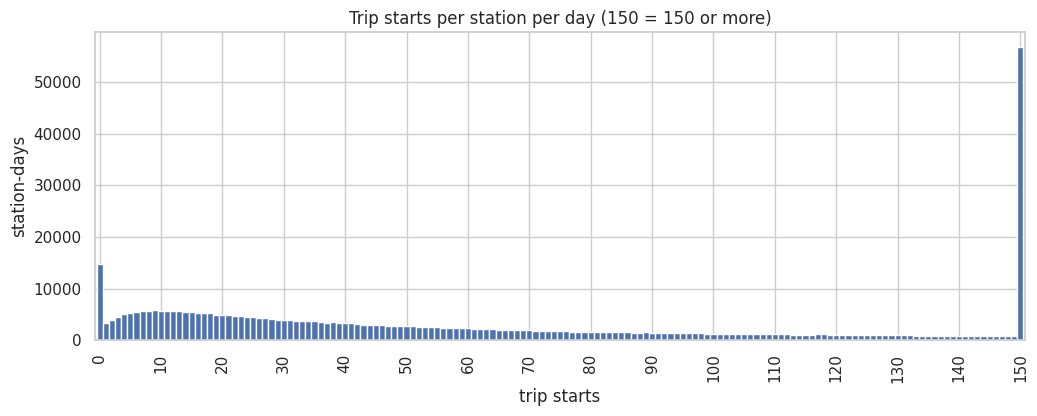

In [27]:
hist = sd.withColumn("bucket", F.least(col("trip_starts"), F.lit(150))).groupBy("bucket").count().toPandas().sort_values("bucket")
ax = hist.plot(x="bucket", y="count", kind="bar", width=1, legend=False)
ax.set_xticks(range(0, 151, 10)); ax.set_xticklabels(range(0, 151, 10))
ax.set_title("Trip starts per station per day (150 = 150 or more)"); ax.set_xlabel("trip starts"); ax.set_ylabel("station-days")
save("D1_target_distribution")

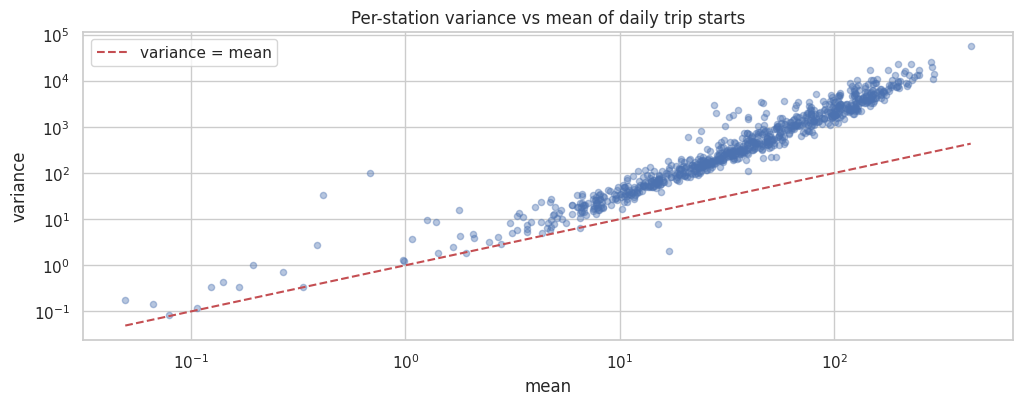

median variance / mean ratio: 9.25


In [28]:
# variance vs mean per station: Poisson assumes variance = mean; much larger variance = over-dispersion
vm = sd.groupBy("station_id").agg(F.mean("trip_starts").alias("mean"), F.variance("trip_starts").alias("variance")).toPandas()
ax = vm.plot(x="mean", y="variance", kind="scatter", alpha=0.4, loglog=True)
lims = [vm["mean"].clip(lower=0.01).min(), vm["mean"].max()]
ax.plot(lims, lims, "r--", label="variance = mean"); ax.legend(); ax.set_title("Per-station variance vs mean of daily trip starts")
save("D2_variance_vs_mean")
print("median variance / mean ratio:", (vm["variance"] / vm["mean"]).median().round(2))

In [29]:
# how well do past days predict today? (supports lag features)
# windows are by calendar day (not by row), so a gap in loaded months never pairs a day with the wrong "last week"
w = Window.partitionBy("station_id").orderBy(F.datediff(col("start_date"), F.lit("2016-01-01")))
def days_back(a, b):
    return w.rangeBetween(-a, -b)
lags = sd.withColumn("lag_1", F.sum("trip_starts").over(days_back(1, 1))) \
         .withColumn("lag_7", F.sum("trip_starts").over(days_back(7, 7))) \
         .withColumn("lag_14", F.sum("trip_starts").over(days_back(14, 14))) \
         .withColumn("rolling_mean_7", F.sum("trip_starts").over(days_back(7, 1)) / 7) \
         .withColumn("rolling_mean_28", F.sum("trip_starts").over(days_back(28, 1)) / 28) \
         .withColumn("days_in_28", F.count("trip_starts").over(days_back(28, 1))) \
         .filter(col("days_in_28") == 28).dropna().cache()   # only days with a full 28-day history
pd.DataFrame({c: [round(lags.stat.corr("trip_starts", c), 3)] for c in ["lag_1", "lag_7", "lag_14", "rolling_mean_7", "rolling_mean_28"]},
             index=["correlation with trip_starts"])

,lag_1,lag_7,lag_14,rolling_mean_7,rolling_mean_28
correlation with trip_starts,0.873,0.883,0.867,0.892,0.88


In [30]:
# preview of the baselines per period: MAE of 'same day last week' (lag-7) and of the 7-day mean
rows = []
for p, (a, b) in periods.items():
    r = lags.filter(col("start_date").between(a, b)).agg(
        F.mean(F.abs(col("trip_starts") - col("lag_7"))), F.mean(F.abs(col("trip_starts") - col("rolling_mean_7"))),
        F.mean("trip_starts"), F.count("*")).collect()[0]
    if r[3] > 0:
        rows.append({"period": p, "MAE lag-7": round(r[0], 3), "MAE 7-day mean": round(r[1], 3), "mean trip_starts": round(r[2], 3)})
pd.DataFrame(rows)

,period,MAE lag-7,MAE 7-day mean,mean trip_starts
0,train 2016,22.141,21.237,78.283
1,tune 2017 Q1,12.875,14.927,39.107
2,test 2017 Q2,24.666,23.231,83.550
3,OOT 2017 Q3+Q4,21.809,20.316,77.828


# Part E. Riders (columns Silver drops)

In [31]:
riders = df.groupBy("user_type").count().toPandas()
riders["pct"] = (100 * riders["count"] / N).round(2)
display(riders)
g = df.groupBy("gender_int").count().toPandas(); g["pct"] = (100 * g["count"] / N).round(2)
print("gender (0 = unknown, 1 = male, 2 = female):"); display(g)

,user_type,count,pct
0,Subscriber,26881036,88.98
1,Customer,3277496,10.85
2,None,51780,0.17


gender (0 = unknown, 1 = male, 2 = female):


,gender_int,count,pct
0,1,20193593,66.84
1,2,6700754,22.18
2,0,3315965,10.98


birth year before 1920: 12123


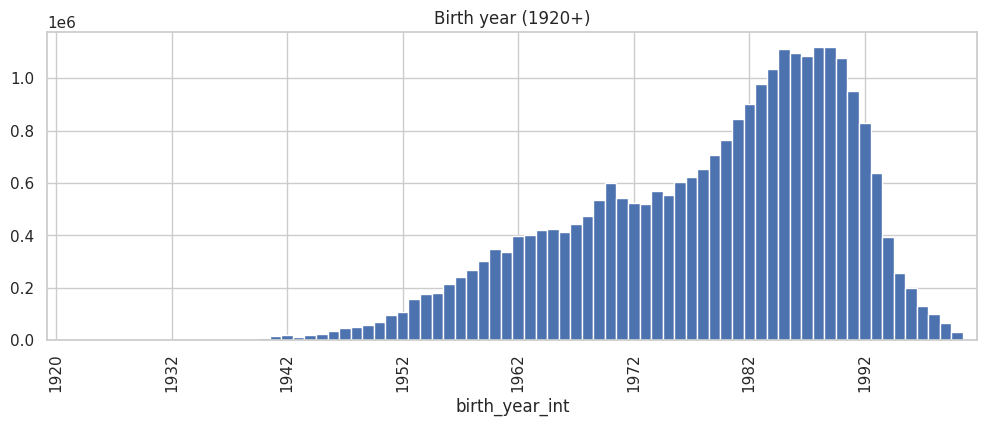

In [32]:
# birth year: missing and implausible values (e.g. before 1920)
by = df.filter(col("birth_year_int").isNotNull()).groupBy("birth_year_int").count().toPandas().sort_values("birth_year_int")
print("birth year before 1920:", int(by[by["birth_year_int"] < 1920]["count"].sum()))
ax = by[by["birth_year_int"] >= 1920].plot(x="birth_year_int", y="count", kind="bar", width=1, legend=False)
ax.set_xticks(range(0, len(by[by["birth_year_int"] >= 1920]), 10)); ax.set_title("Birth year (1920+)")
save("E1_birth_year")

In [33]:
# subscribers vs customers by day type (customers = tourists/leisure, peak at weekends)
ut = df.filter(col("start_ts").isNotNull()).withColumn("is_weekend", F.dayofweek("start_date").isin(1, 7)).groupBy("is_weekend", "user_type").count().toPandas() \
       .pivot(index="user_type", columns="is_weekend", values="count")
(100 * ut / ut.sum()).round(1)

is_weekend,False,True
user_type,,
NaN,0.1,0.3
Customer,7.6,21.2
Subscriber,92.2,78.5


# Part F. Findings → decisions

From the full run on all of 2016–2017 (30,210,312 raw trips, 731 days). Each row points to the section above it came from. This table goes almost directly into the report.

| # | Finding (with number) | Decision | Layer |
|---|---|---|---|
| 1 | Two header styles ("tripduration" vs "Trip Duration", Oct 2016–Mar 2017) and two date formats (M/d/yyyy until Sep 2016, yyyy-MM-dd after); busy months split into 2 CSVs (A1) | Bronze keeps every column as text; Silver maps both header styles and both date formats to one schema | Bronze / Silver |
| 2 | No missing start/stop time, station id or coordinate; 0 values that fail to parse; 0 exact duplicates (A2–A4) | keep these checks anyway as data-quality guards for new files; they cost little | Silver |
| 3 | 7,746 trips over 24 h (max 113 days), 63,709 over 3 h, 0 under 60 s, 132 with stop before start on clock-change days (A5) | drop over 24 h (lost or broken bikes); keep 3–24 h (real long rides); ignore stop-before-start, since stop time is not used for the target | Silver |
| 4 | 17 depot / test / warehouse / ops stations, about 4,900 trips, e.g. "NYCBS Depot - SSP", "8D OPS 01", "333 Johnson TEST 1"; two of them are outside NYC (Montreal, and 38.4, -69.6) (C1) | drop trips that start or end at them (station-name rule); keep "Penn Station Valet" and "Union Ave & Wallabout St", which are real stations | Silver |
| 5 | Coordinates: 46 start / 161 end are 0; 128 start / 244 end are outside the NYC area (C1) | drop trips with any coordinate missing, 0 or outside NYC (lat 40.4–41.0, lon -74.3 to -73.6) | Silver |
| 6 | 844 start station ids; 21 ids had more than one name, 16 more than one location, 9 names were used by more than one id (C1) | station_id is the key; names and coordinates are for display only | Silver / Gold |
| 7 | user_type missing 0.17% (only Oct 2016–Mar 2017); birth year missing 10.6% and 12,123 before 1920; gender unknown 11% (A2, E) | drop rider columns: not needed for station demand, and less personal data | Silver |
| 8 | 8 days with 0 trips: 23–26 Jan 2016, 9 Feb 2017, 14–16 Mar 2017 (snowstorm shutdowns); March 2017 is 21% below March 2016 because of it (B1, B2) | keep as real 0 labels; snowfall from the weather data should explain them; mention in the report | Gold |
| 9 | Strong seasons and growth: 2017 about 20% above 2016; mean trips/day: train 37.8k, tune Q1 25.0k, test Q2 50.2k, OOT 51.9k (B1, B2) | use lag and rolling features (they follow the level) plus fe_month; no year feature; note in the report that tuning happens in winter but testing in spring | Gold / Model |
| 10 | Weekly pattern: Tue–Thu busiest, weekends about 30% lower; weekday peaks at 8 am and 5–6 pm, weekend midday; customers are 21% of weekend trips vs 8% on weekdays (B3, E) | fe_day_of_week, fe_is_weekend; the target stays daily, and the hourly peaks go in the report only | Gold |
| 11 | Stations grew from 472 (Jan 2016) to 752 (Dec 2017), in two big expansions: Aug–Sep 2016 (+141) and Sep–Oct 2017 (+142, inside the OOT period) (C2) | active-station rule (at least 1 trip in the prior 28 days); new stations without history fall back to the baseline | Gold |
| 12 | Demand is concentrated: the top 10% of stations make 35.5% of trips, the top 20% make 58.2% (C2) | also report MAE for busy vs quiet stations (segment / bias check) | Monitoring |
| 13 | Target per station-day: mean 70.8, median 45, p99 334, max 945, 3.4% zeros (D) | count target, skewed right: Poisson-type objective, MAE as the metric | Model |
| 14 | Over-dispersion: median variance/mean per station is 9.25 (Poisson assumes 1) (D) | expect plain Poisson regression to be weaker; XGBoost count:poisson still predicts the mean fine | Model |
| 15 | Past demand predicts today well: correlation lag_1 0.873, lag_7 0.883, lag_14 0.867, 7-day mean 0.892, 28-day mean 0.880 (D) | keep all five as features in the Gold feature store | Gold |
| 16 | Lag-7 baseline MAE: train 22.1, tune 12.9, test Q2 24.7, OOT 21.8; the 7-day mean already gets 23.2 on test (D) | acceptance target: model MAE ≤ 22.2 on 2017 Q2 (10% better than lag-7); the 7-day mean is a second baseline to beat | Model |

In [34]:
spark.stop()